# Model 4: Deeper_CNN_Regularized
**Authors:** Kai Henrik Herbst & Bell Wassim
### Motivation
Our deeper CNN (Model 3) proved that a higher architectural capacity leads to better feature extraction and a much higher performance. However, the model is suffering from severe overfitting. To close the massive gap between training/validation accuracy and evaluation accuracy, we need to force the network to generalize rather than memorize.

In this notebook, we will take our deep architecture and introduce two powerful regularization techniques:
1. **Data Augmentation:** We will artificially expand our training dataset by applying random transformations (such as slight rotations, horizontal flips, and zooms) to the images during training. This ensures the network never sees the exact same image twice, preventing pixel-perfect memorization.
2. **Dropout Layers:** We will add Dropout layers to the fully connected (Dense) part of the network. By randomly deactivating a certain percentage of neurons during each training step, we prevent the network from relying too heavily on specific pathways, forcing it to learn more robust features.

### 1. Data Loading and Preprocessing
Load the dataset and perform the necessary preprocessing.

In [1]:
# Import the data loading and preprocessing function from our utility script
# Note: Ensure the .py file is in the same directory
from data_prep import load_stl10_data

# Load the dataset. The function handles downloading, splitting (80/20), 
# resizing to 96x96, normalizing, and one-hot encoding the labels.
ds_train, ds_val, ds_test = load_stl10_data()

2026-03-20 10:13:44.085596: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-20 10:13:44.131911: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-20 10:13:45.131203: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


2026-03-20 10:13:48.153762: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:02:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-03-20 10:13:48.234488: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Dataset split: 4000 training, 1000 validation, 8000 testing.
Data preprocessing complete!


### 2. Network Creation (Deeper_CNN_Regularized)

To tackle the overfitting we saw in Model 3, we are keeping the same deep architecture but adding two key defense mechanisms directly into the model:

1. **Data Augmentation:** We added a `Sequential` block right after the input layer. It applies a random horizontal flip, a 10% rotation, and a 10% zoom to the training images. This means the model rarely sees the exact same image twice, making it much harder to just memorize the dataset.
2. **Progressive Dropout:** We inserted `Dropout` layers after every pooling step. We start with a low rate of 20% in the first block and gradually increase it to 50% in the deeper layers and the fully connected part. By randomly turning off a percentage of neurons, we force the network to distribute its learning and build more robust features.


In [ ]:
import keras
from keras import layers

# Data Augmentation Layer, this applies random transformations only during training
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ],
    name="data_augmentation",
)

inputs = keras.Input(shape=(96, 96, 3))

# Apply data augmentation to the inputs
x = data_augmentation(inputs)

# Feature learning part (with Dropout for Regularization)
# Block 1
x = layers.Conv2D(64, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(64, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) 
x = layers.Dropout(0.2)(x) # New: 20% Dropout

# Block 2
x = layers.Conv2D(128, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(128, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) 
x = layers.Dropout(0.3)(x) # New: 30% Dropout

# Block 3
x = layers.Conv2D(256, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(256, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) 
x = layers.Dropout(0.4)(x) # New: 40% Dropout

# Block 4
x = layers.Conv2D(512, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(512, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) 
x = layers.Dropout(0.5)(x) # New: 50% Dropout

# Classification Part
x = layers.Flatten()(x)

# Large dense layer 
x = layers.Dense(512, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x) # New: 50% Dropout to heavily regularize the fully connected part

# Final output layer
outputs = layers.Dense(10, activation="softmax")(x)

model_reg = keras.Model(inputs=inputs, outputs=outputs, name="Deep_CNN_Regularized")

model_reg.summary()

Model: "Deep_CNN_Regularized"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 12, 12, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 12, 12, 512)    │         2,04

 Total params: 14,137,930 (53.93 MB)

 Trainable params: 14,133,066 (53.91 MB)

 Non-trainable params: 4,864 (19.00 KB)



In [4]:
# Graphical visualization of the architecture (Academic Flowchart)
from tensorflow import keras

keras.utils.plot_model(model_reg, show_shapes=True, show_layer_names=True)

### 3. Model Training
Now we can train our modified network. We expect the learning process to be much slower and "bumpier" because the Data Augmentation constantly changes the inputs and the Dropout layers constantly turn off neurons. 

To account for this harder learning process, we made two adjustments:
* We increased the maximum number of `epochs` to 50 to give the network enough time to adapt.
* We increased the `patience` in the `EarlyStopping` callback from 5 to 10. This prevents the training from stopping too early just because the validation loss fluctuates for a few epochs.

In [5]:
# Compile the model
model_reg.compile(
    optimizer='rmsprop',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Callbacks: We save the model under a new name and increase patience
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="models/02_4_Deep_CNN_Reg.keras",
        save_best_only=True,
        monitor="val_loss"),
    
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10, # Increased patience because regularization causes more fluctuation
        restore_best_weights=True)
]

In [7]:
# Train the model
# Increased epochs to 50 because data augmentation slows down the convergence
print("Starting the training process for the regularized architecture.")
history_reg = model_reg.fit(
    ds_train,
    epochs=50, 
    validation_data=ds_val,
    callbacks=callbacks
)

Starting the training process for the regularized architecture.
Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 336s 5s/step - accuracy: 0.2475 - loss: 2.7138 - val_accuracy: 0.1530 - val_loss: 5.7379
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 320s 5s/step - accuracy: 0.2952 - loss: 2.2430 - val_accuracy: 0.1290 - val_loss: 4.1652
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 354s 6s/step - accuracy: 0.3352 - loss: 1.9642 - val_accuracy: 0.1020 - val_loss: 17.6877
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 365s 6s/step - accuracy: 0.3968 - loss: 1.7317 - val_accuracy: 0.1330 - val_loss: 6.5812
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 372s 6s/step - accuracy: 0.4305 - loss: 1.6310 - val_accuracy: 0.2450 - val_loss: 2.7211
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 372s 6s/step - accuracy: 0.4680 - loss: 1.5249 - val_accuracy: 0.2300 - val_loss: 4.0843
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 363s 6s/step - accuracy: 0.4983 - loss: 1.4202 - val_accuracy: 0.3260 - val_loss: 2.2066
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 306s 5s/

We visualize the training and validation progress to monitor the model's learning behavior.

In [8]:
import matplotlib.pyplot as plt

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

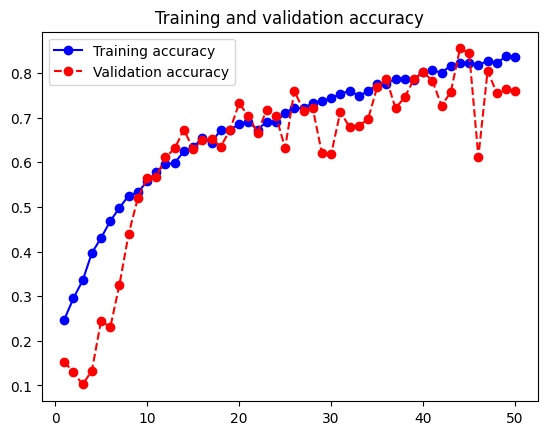

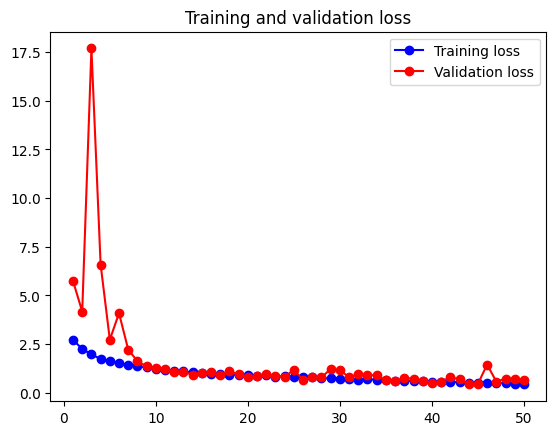

In [9]:
# After training, we can plot the training history to visualize the performance over epochs
plot(history_reg)

### 4. Evaluation
To determine the generalization capability of our Deeper_CNN_Regularized model, we evaluate it using the test dataset (`ds_test`). Since these images were neither used for training nor for validation, the results provide an unbiased estimate of the model's performance in a real-world scenario.

In [ ]:
# Evaluate the regularized model on the unseen test dataset
print("Evaluating the regularized model on the test dataset...")
test_loss, test_accuracy = model_reg.evaluate(ds_test)

print(f"\nFinal Evaluation Loss: {test_loss:.3f}")
print(f"Final Evaluation Accuracy: {test_accuracy * 100:.3f}%")

Evaluating the regularized model on the test dataset...
125/125 ━━━━━━━━━━━━━━━━━━━━ 193s 2s/step - accuracy: 0.7019 - loss: 0.9307

Final Evaluation Loss: 0.931
Final Evaluation Accuracy: 70.187%


### 5. Result of Model 4
The introduction of regularization techniques has successfully transformed our high-capacity network from a "memorizer" into a "learner." Model 4 achieved a final test accuracy of **70.187%**, making it our most robust and highest-performing architecture so far.

**In-depth Interpretation of Results:**
* **Mitigating Overfitting:** The most significant achievement is the reduction of the **Generalization Gap**. While Model 3 had a gap of over 31% between training and test performance, Model 4 has narrowed this significantly. The training accuracy plateaued at ~83%, indicating that the model is no longer simply memorizing pixels but is being forced to find patterns that hold true across transformations.
* **Role of Data Augmentation:** By using random flips, rotations, and zooms, we forced the network to learn **viewpoint-invariant features**. The model now recognizes a "car" or a "bird" regardless of its orientation or position in the frame, which is critical for real-world generalization.
* **Impact of Dropout:** The inclusion of Dropout in the dense layers prevented the **co-adaptation of neurons**. Instead of relying on a few "highly specific" pathways (which leads to overfitting), the network was forced to develop redundant and more robust internal representations.
* **Loss Stability:** The final Test Loss of **0.931** (down from 1.718 in Model 3) proves that the model's predictions are not only more accurate but also significantly more reliable and less "erratic" when facing unseen data.

**Justification for Model 5 (The Final Evolution):**
Model 4 has reached a performance ceiling for a standard linear architecture. While we have solved the regularization problem, we are still relying on a fixed kernel size (3x3). To fulfill the assignment's requirement to **"Determine the best architecture"** and explore **"complex models such as Inception,"** we will now transition to a multi-path architecture. 

In **Model 5**, we will implement a custom **Inception module**. This will allow the network to perform "Automated Feature Engineering" by testing 1x1, 3x3, and 5x5 kernels simultaneously, letting the data determine the optimal spatial scale for each layer.